# Retail Product Association Analysis

## Problem Statement
Online retailers need to understand which products are frequently bought together so they can design better product recommendations, promotions, and store layouts.

## Objectives
1. Clean and prepare the UCI Online Retail dataset for market-basket analysis.
2. Discover frequent itemsets using the FP-Growth algorithm.
3. Generate association rules and evaluate them on unseen baskets.
4. Compare the runtime performance of FP-Growth versus Apriori.
5. Visualise patterns and interpret the strongest rules for business use.

In [2]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")
print(df.shape)      #num of rows n column
print(df.head())     #display the first five rows
print(df.info())     #provides a summary of the DataFrame.
print(df.isna().sum())  #checks and display missing values

(541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------      

Remove cancelled INVOICE

In [3]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)   #convert invoice column into strings why? cuz some are numbers, some are text
print(df["InvoiceNo"].str.startswith("C").sum()) #display invoice starting with C
df = df[~df["InvoiceNo"].str.startswith("C")] #invoice records starting with C are removed.
print(len(df))            #~ means “not”, so Keep invoices that do NOT start with C.

9288
532621


Remove impossible values

In [4]:
print((df["Quantity"] <= 0).sum(), (df["UnitPrice"] <= 0).sum())  #checks how many rows contain zero or negative values
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]
print(len(df))

1336 2517
530104


Remove rows with a missing product name




In [5]:
df = df.dropna(subset=["Description"])
print(len(df))

530104


In [6]:
df["StockCode"] = df["StockCode"].astype(str).str.strip().str.upper()

# look first: what would be removed?
nonprod = df[~df["StockCode"].str.match(r"^\d{5}")]
print(nonprod["StockCode"].value_counts().head(20))

# now remove them
df = df[df["StockCode"].str.match(r"^\d{5}")]
print(len(df))

StockCode
POST            1126
DOT              706
M                322
C2               141
DCGSSGIRL         13
BANK CHARGES      12
DCGSSBOY          11
GIFT_0001_20       9
GIFT_0001_10       8
GIFT_0001_30       7
DCGS0003           4
GIFT_0001_50       4
GIFT_0001_40       3
PADS               3
S                  2
DCGS0076           2
AMAZONFEE          2
DCGS0070           1
DCGS0069           1
DCGS0004           1
Name: count, dtype: int64
527725


Remove exact duplicates

In [7]:
print(df.duplicated().sum())
df = df.drop_duplicates()
print(len(df))

5221
522504


Give each product one consistent name,  performs data standardisation and inconsistency correction

In [8]:
# check the problem first
n = df.groupby("StockCode")["Description"].nunique()
print((n > 1).sum(), "stock codes have more than one description")

df["Description"] = df["Description"].str.strip().str.upper()

# most common description for each stock code
canon = df.groupby("StockCode")["Description"].agg(lambda s: s.value_counts().index[0])
df["Description"] = df["StockCode"].map(canon)

215 stock codes have more than one description


Final Check

In [9]:
print(df.shape, df["InvoiceNo"].nunique(), df["StockCode"].nunique())
df = df.reset_index(drop=True)
df.to_csv("cleaned_retail.csv", index=False)

(522504, 8) 19773 3791


In [10]:
from google.colab import files
files.download("cleaned_retail.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [11]:
import pandas as pd
check = pd.read_csv("cleaned_retail.csv")
print(check.shape, check["InvoiceNo"].nunique(), check["StockCode"].nunique())

(522504, 8) 19773 3791


In [12]:
import pandas as pd
df = pd.read_csv("cleaned_retail.csv")
print(df.shape)

(522504, 8)


EDA

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Shape after cleaning:", df.shape)
print("Unique invoices :", df["InvoiceNo"].nunique())
print("Unique products :", df["StockCode"].nunique())
print("Unique customers:", df["CustomerID"].nunique())
print()
print("Quantity statistics:")
print(df["Quantity"].describe().round(2))
print()
print("UnitPrice statistics:")
print(df["UnitPrice"].describe().round(2))

Shape after cleaning: (522504, 8)
Unique invoices : 19773
Unique products : 3791
Unique customers: 4334

Quantity statistics:
count    522504.00
mean         10.64
std         156.60
min           1.00
25%           1.00
50%           4.00
75%          12.00
max       80995.00
Name: Quantity, dtype: float64

UnitPrice statistics:
count    522504.00
mean          3.27
std           4.39
min           0.04
25%           1.25
50%           2.08
75%           4.13
max         649.50
Name: UnitPrice, dtype: float64


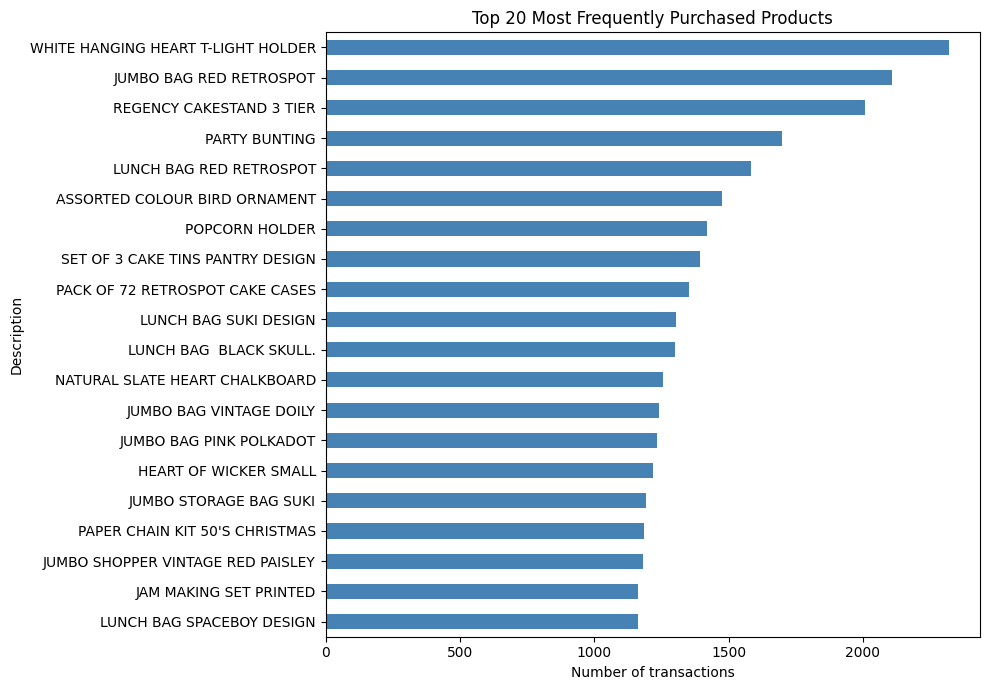

In [14]:
# Top 20 most frequent products
top20 = df["Description"].value_counts().head(20)

plt.figure(figsize=(10, 7))
top20.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 20 Most Frequently Purchased Products")
plt.xlabel("Number of transactions")
plt.tight_layout()
plt.show()

Keep UK orders only


In [15]:
print(df["Country"].value_counts().head(5))
df = df[df["Country"] == "United Kingdom"]
print(len(df), df["InvoiceNo"].nunique())

Country
United Kingdom    478838
Germany             8643
France              8085
EIRE                7768
Spain               2417
Name: count, dtype: int64
478838 17901


keep the 150 most popular items

In [16]:
top_items = df["Description"].value_counts().head(150).index
df = df[df["Description"].isin(top_items)]
print(df["Description"].nunique())

150


Build the basket matrix

In [17]:
basket = (df.groupby(["InvoiceNo", "Description"]).size().unstack(fill_value=0) > 0)
print(basket.shape)
basket.iloc[:5, :5]

(15209, 150)


Description,6 RIBBONS RUSTIC CHARM,60 CAKE CASES VINTAGE CHRISTMAS,60 TEATIME FAIRY CAKE CASES,72 SWEETHEART FAIRY CAKE CASES,ALARM CLOCK BAKELIKE GREEN
InvoiceNo,,,,,
536365,False,False,False,False,False
536367,False,False,False,False,False
536368,False,False,False,False,False
536371,False,False,False,False,False
536373,False,False,False,False,False


remove one-item baskets

In [18]:
basket = basket[basket.sum(axis=1) >= 2]
print(basket.shape)

(12884, 150)


Final basket matrix shape: (12884, 150)
Average items per basket : 8.95


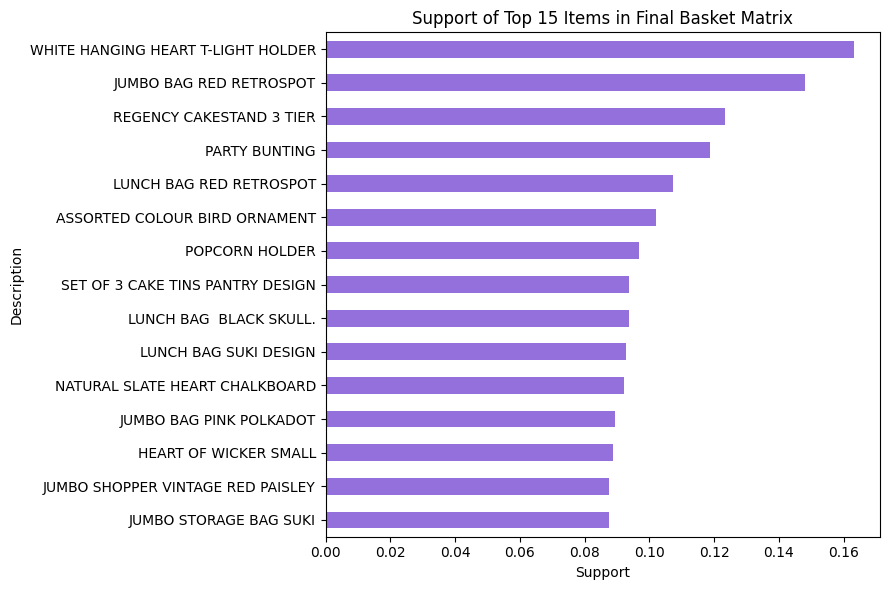

In [19]:
print("Final basket matrix shape:", basket.shape)
print("Average items per basket :", round(basket.sum(axis=1).mean(), 2))

item_freq = basket.mean().sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
item_freq.sort_values().plot(kind="barh", color="mediumpurple")
plt.title("Support of Top 15 Items in Final Basket Matrix")
plt.xlabel("Support")
plt.tight_layout()
plt.show()

train/test split

In [20]:
train = basket.sample(frac=0.8, random_state=42)
test = basket.drop(train.index)
print(len(train), len(test))

10307 2577


In [21]:
!pip install mlxtend==0.23.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.3 MB/s  0:00:00
  Attempting uninstall: mlxtend
    Found existing installation: mlxtend 0.23.4
    Uninstalling mlxtend-0.23.4:
      Successfully uninstalled mlxtend-0.23.4


Run FP-Growth

In [22]:
from mlxtend.frequent_patterns import fpgrowth, association_rules
import time

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
start = time.time()
itemsets = fpgrowth(train, min_support=0.02, use_colnames=True)
print(len(itemsets), "frequent itemsets in", round(time.time() - start, 2), "sec")

sizes = itemsets["itemsets"].apply(len)
print(sizes.value_counts().sort_index())

itemsets.sort_values("support", ascending=False).head(10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

514 frequent itemsets in 1.51 sec
itemsets
1    150
2    305
3     58
4      1
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
72,0.164160,(WHITE HANGING HEART T-LIGHT HOLDER)
31,0.148540,(JUMBO BAG RED RETROSPOT)
117,0.124479,(REGENCY CAKESTAND 3 TIER)
83,0.119239,(PARTY BUNTING)
3,0.110119,(LUNCH BAG RED RETROSPOT)
0,0.102358,(ASSORTED COLOUR BIRD ORNAMENT)
42,0.096245,(POPCORN HOLDER)
13,0.094984,(LUNCH BAG BLACK SKULL.)
14,0.094402,(LUNCH BAG SUKI DESIGN)
55,0.094014,(SET OF 3 CAKE TINS PANTRY DESIGN)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Turn itemsets into rules

In [24]:
rules = association_rules(itemsets, metric="confidence", min_threshold=0.3)
print(len(rules), "rules with confidence >= 0.3")

rules = rules[rules["lift"] > 1]
print(len(rules), "rules after keeping lift > 1")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

612 rules with confidence >= 0.3
612 rules after keeping lift > 1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

View the rules readably

In [25]:
show = rules.copy()
show["antecedents"] = show["antecedents"].apply(lambda s: ", ".join(sorted(s)))
show["consequents"] = show["consequents"].apply(lambda s: ", ".join(sorted(s)))
show.sort_values("lift", ascending=False)[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].head(10).round(3)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
282,JUMBO BAG PEARS,"JUMBO BAG APPLES, JUMBO BAG VINTAGE DOILY",0.021,0.475,14.713
279,"JUMBO BAG APPLES, JUMBO BAG VINTAGE DOILY",JUMBO BAG PEARS,0.021,0.637,14.713
585,"CHARLOTTE BAG PINK POLKADOT, CHARLOTTE BAG SUK...",WOODLAND CHARLOTTE BAG,0.021,0.722,13.382
586,WOODLAND CHARLOTTE BAG,"CHARLOTTE BAG PINK POLKADOT, CHARLOTTE BAG SUK...",0.021,0.392,13.382
520,WOODLAND CHARLOTTE BAG,"CHARLOTTE BAG SUKI DESIGN, STRAWBERRY CHARLOTT...",0.022,0.405,13.326
519,"CHARLOTTE BAG SUKI DESIGN, STRAWBERRY CHARLOTT...",WOODLAND CHARLOTTE BAG,0.022,0.719,13.326
514,STRAWBERRY CHARLOTTE BAG,"RED RETROSPOT CHARLOTTE BAG, WOODLAND CHARLOTT...",0.024,0.451,13.287
513,"RED RETROSPOT CHARLOTTE BAG, WOODLAND CHARLOTT...",STRAWBERRY CHARLOTTE BAG,0.024,0.700,13.287
577,"RED RETROSPOT CHARLOTTE BAG, WOODLAND CHARLOTT...",CHARLOTTE BAG PINK POLKADOT,0.023,0.689,13.167
582,CHARLOTTE BAG PINK POLKADOT,"RED RETROSPOT CHARLOTTE BAG, WOODLAND CHARLOTT...",0.023,0.447,13.167


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

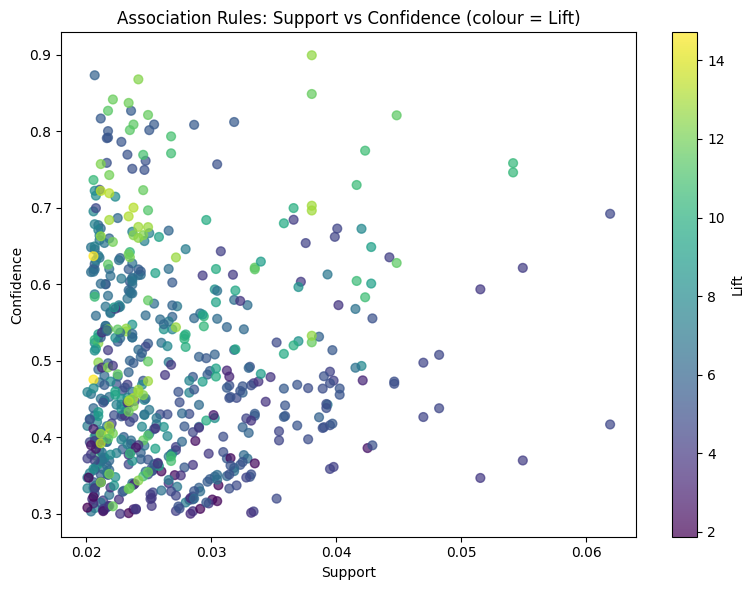

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [26]:
# 1. Support vs Confidence scatter plot
plt.figure(figsize=(8, 6))
sc = plt.scatter(rules["support"], rules["confidence"],
                 c=rules["lift"], cmap="viridis", alpha=0.7, s=40)
plt.colorbar(sc, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association Rules: Support vs Confidence (colour = Lift)")
plt.tight_layout()
plt.show()

Compare FP-Growth and Apriori







In [27]:
from mlxtend.frequent_patterns import apriori

rows = []
for s in [0.05, 0.03, 0.02, 0.015]:
    t = time.time(); fp = fpgrowth(train, min_support=s, use_colnames=True); t_fp = time.time() - t
    t = time.time(); ap = apriori(train, min_support=s, use_colnames=True); t_ap = time.time() - t
    rows.append({"min_support": s, "fpgrowth_sec": t_fp, "apriori_sec": t_ap,
                 "itemsets_fp": len(fp), "itemsets_ap": len(ap)})
pd.DataFrame(rows).round(2)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,min_support,fpgrowth_sec,apriori_sec,itemsets_fp,itemsets_ap
0,0.05,0.46,0.25,93,93
1,0.03,1.03,0.82,237,237
2,0.02,1.06,1.80,514,514
3,0.02,1.19,4.41,1124,1124


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Test the rules on unseen baskets

In [28]:
import random
random.seed(42)

# keep rules with a single item on the "then" side, as (if-items, then-item, lift)
single = rules[rules["consequents"].apply(len) == 1]
rule_list = [(set(a), next(iter(c)), l)
             for a, c, l in zip(single["antecedents"], single["consequents"], single["lift"])]

hits = covered = total = 0
for _, row in test.iterrows():
    items = list(row[row].index)          # items in this basket
    hidden = random.choice(items)         # hide one
    visible = set(items) - {hidden}
    preds = {}
    for ant, con, lift in rule_list:
        if ant <= visible and con not in visible:      # rule fires
            preds[con] = max(preds.get(con, 0), lift)
    total += 1
    if preds:
        covered += 1
        top5 = sorted(preds, key=preds.get, reverse=True)[:5]
        hits += hidden in top5

print("Hit rate@5:", round(hits / total, 3))
print("Coverage:", round(covered / total, 3))
print("Precision when covered:", round(hits / covered, 3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Hit rate@5: 0.274
Coverage: 0.872
Precision when covered: 0.315


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Store the Apriori comparison

In [29]:
comp = pd.DataFrame(rows).round(3)
comp

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,min_support,fpgrowth_sec,apriori_sec,itemsets_fp,itemsets_ap
0,0.050,0.458,0.250,93,93
1,0.030,1.031,0.825,237,237
2,0.020,1.059,1.797,514,514
3,0.015,1.187,4.413,1124,1124


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

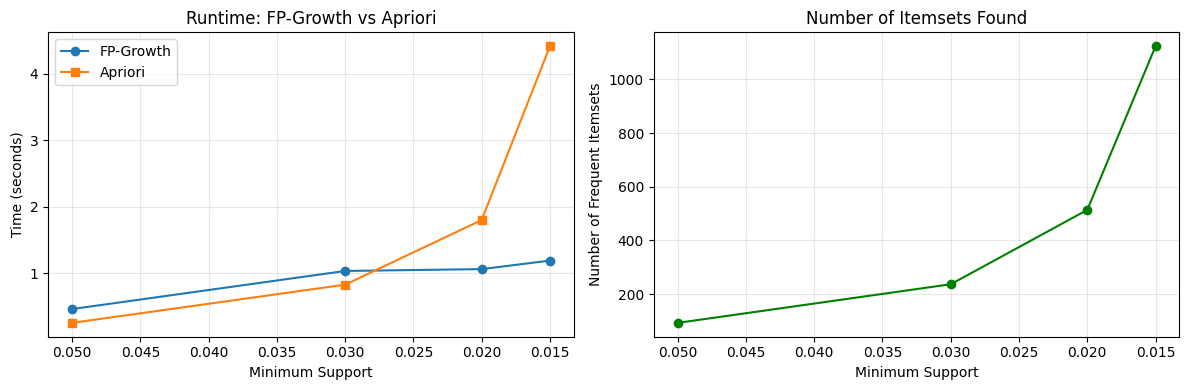

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [30]:
# Runtime comparison plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(comp["min_support"], comp["fpgrowth_sec"], "o-", label="FP-Growth")
ax[0].plot(comp["min_support"], comp["apriori_sec"], "s-", label="Apriori")
ax[0].set_xlabel("Minimum Support")
ax[0].set_ylabel("Time (seconds)")
ax[0].set_title("Runtime: FP-Growth vs Apriori")
ax[0].legend()
ax[0].invert_xaxis()
ax[0].grid(alpha=0.3)

ax[1].plot(comp["min_support"], comp["itemsets_fp"], "o-", color="green")
ax[1].set_xlabel("Minimum Support")
ax[1].set_ylabel("Number of Frequent Itemsets")
ax[1].set_title("Number of Itemsets Found")
ax[1].invert_xaxis()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Store the evaluation numbers

In [31]:
metrics = {"hit_rate_at_5": hits / total, "coverage": covered / total,
           "precision_when_covered": hits / covered, "n_test_baskets": total}
metrics

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

{'hit_rate_at_5': 0.2743500194024059,
 'coverage': 0.8723321691889794,
 'precision_when_covered': 0.3145017793594306,
 'n_test_baskets': 2577}

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


save to sqlite


In [ ]:
import numpy as np
import sqlite3

# 1. Rules: SQLite cannot store sets, so turn the item groups into text
r = rules.copy()
r["antecedents"] = r["antecedents"].apply(lambda s: ", ".join(sorted(s)))
r["consequents"] = r["consequents"].apply(lambda s: ", ".join(sorted(s)))
r = r[["antecedents", "consequents", "support", "confidence", "lift", "leverage", "conviction"]]
r = r.replace([np.inf, -np.inf], np.nan)          # conviction is infinite when confidence = 1

# 2. Write the three tables the dashboard needs into basket.db
con = sqlite3.connect("basket.db")
r.to_sql("rules", con, if_exists="replace", index=False)
comp.to_sql("runtime_comparison", con, if_exists="replace", index=False)
pd.DataFrame([metrics]).to_sql("evaluation", con, if_exists="replace", index=False)

# 3. Check
for t in ["rules", "runtime_comparison", "evaluation"]:
    print(t, pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", con).iloc[0, 0], "rows")
con.close()

In [ ]:
from google.colab import files
files.download("basket.db")